# 🇪🇹 Ethiopian Used Car Price Prediction
## Using Linear Regression

---

This project predicts the **selling price of used cars in Ethiopia** (in Ethiopian Birr - ETB) based on features such as car model, year, mileage, fuel type, and more.

**Data Source:** Inspired by real listings from [mekina.net](https://www.mekina.net/) and [jiji.com.et](https://jiji.com.et/cars)

**Currency:** Ethiopian Birr (ETB) — approximate rate: 1 USD ≈ 160 ETB (2026)

### Popular Cars in Ethiopian Market:
| Brand | Model | Price Range (ETB) |
|---|---|---|
| Toyota | Corolla | 2.1M – 5.9M |
| Toyota | Hilux | 5.0M – 11.5M |
| Toyota | Land Cruiser | 9.5M – 30M |
| Hyundai | i10 | 1.5M – 3.2M |
| Suzuki | Dzire / Swift | 2.1M – 3.9M |
| Nissan | Patrol | 10.5M – 24M |

## 1. Importing Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Make plots look nice
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
sns.set_theme(style='whitegrid')

print('Libraries imported successfully!')

Libraries imported successfully!


## 2. Loading the Ethiopian Car Dataset

In [ ]:
# Load the dataset using a relative path
data = pd.read_csv('ethiopia_car_data.csv')
print(f'Dataset loaded! Shape: {data.shape}')
data.head(10)

Dataset loaded! Shape: (227, 9)


,Car_Name,Year,Selling_Price_ETB,Present_Price_ETB,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,Toyota Corolla,2015,3800000,5200000,85000,Petrol,Dealer,Manual,0
1,Toyota Corolla,2018,4800000,5700000,45000,Petrol,Dealer,Manual,0
2,Toyota Corolla,2020,5200000,6000000,30000,Petrol,Dealer,Manual,0
3,Toyota Corolla,2012,3200000,5200000,120000,Petrol,Dealer,Manual,0
4,Toyota Corolla,2010,2900000,5200000,150000,Petrol,Individual,Manual,1
5,Toyota Corolla,2008,2600000,5200000,180000,Petrol,Individual,Manual,1
6,Toyota Corolla,2005,2300000,5200000,210000,Petrol,Individual,Manual,2
7,Toyota Corolla,2022,5600000,6200000,15000,Petrol,Dealer,Automatic,0
8,Toyota Corolla,2019,5000000,5900000,38000,Petrol,Dealer,Automatic,0
9,Toyota Corolla,2016,4100000,5400000,72000,Petrol,Dealer,Manual,0


## 3. Exploratory Data Analysis (EDA)

In [ ]:
# Dataset info
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 227 entries, 0 to 226
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Car_Name           227 non-null    str  
 1   Year               227 non-null    int64
 2   Selling_Price_ETB  227 non-null    int64
 3   Present_Price_ETB  227 non-null    int64
 4   Kms_Driven         227 non-null    int64
 5   Fuel_Type          227 non-null    str  
 6   Seller_Type        227 non-null    str  
 7   Transmission       227 non-null    str  
 8   Owner              227 non-null    int64
dtypes: int64(5), str(4)
memory usage: 16.1 KB


In [ ]:
# Statistical summary
data.describe()

,Year,Selling_Price_ETB,Present_Price_ETB,Kms_Driven,Owner
count,227.000000,2.270000e+02,2.270000e+02,227.000000,227.000000
mean,2016.334802,7.950000e+06,1.087868e+07,69149.779736,0.286344
std,4.028963,5.999580e+06,7.371091e+06,47038.155642,0.603777
min,2003.000000,1.500000e+06,2.700000e+06,3000.000000,0.000000
25%,2014.000000,3.200000e+06,5.200000e+06,30000.000000,0.000000
50%,2016.000000,6.000000e+06,9.000000e+06,62000.000000,0.000000
75%,2020.000000,1.075000e+07,1.490000e+07,96500.000000,0.000000
max,2024.000000,3.000000e+07,3.500000e+07,240000.000000,3.000000


In [ ]:
# Check for missing values
print('Missing values per column:')
print(data.isnull().sum())

Missing values per column:
Car_Name             0
Year                 0
Selling_Price_ETB    0
Present_Price_ETB    0
Kms_Driven           0
Fuel_Type            0
Seller_Type          0
Transmission         0
Owner                0
dtype: int64


In [ ]:
# Categorical column value counts
print('=== Fuel Type ===')
print(data['Fuel_Type'].value_counts())
print('\n=== Seller Type ===')
print(data['Seller_Type'].value_counts())
print('\n=== Transmission ===')
print(data['Transmission'].value_counts())
print('\n=== Owner ===')
print(data['Owner'].value_counts())

=== Fuel Type ===
Fuel_Type
Petrol    146
Diesel     81
Name: count, dtype: int64

=== Seller Type ===
Seller_Type
Dealer        186
Individual     41
Name: count, dtype: int64

=== Transmission ===
Transmission
Automatic    151
Manual        76
Name: count, dtype: int64

=== Owner ===
Owner
0    177
1     38
2      9
3      3
Name: count, dtype: int64


In [ ]:
# Top car models
print('=== Top Car Models in Ethiopian Market ===')
print(data['Car_Name'].value_counts())

=== Top Car Models in Ethiopian Market ===
Car_Name
Toyota Corolla         24
Toyota Hilux           19
Toyota Land Cruiser    16
Hyundai i10            14
Toyota Vitz            13
Toyota Fortuner        13
Hyundai Avante         13
Suzuki Dzire           12
Suzuki Swift           12
Nissan Patrol          12
Toyota RAV4            12
Hyundai Tucson         11
Honda Accord           11
Toyota Camry           11
Suzuki Ertiga           9
Volkswagen Golf         9
Mitsubishi Pajero       8
Hyundai Santa Fe        8
Name: count, dtype: int64


## 4. Visualizations

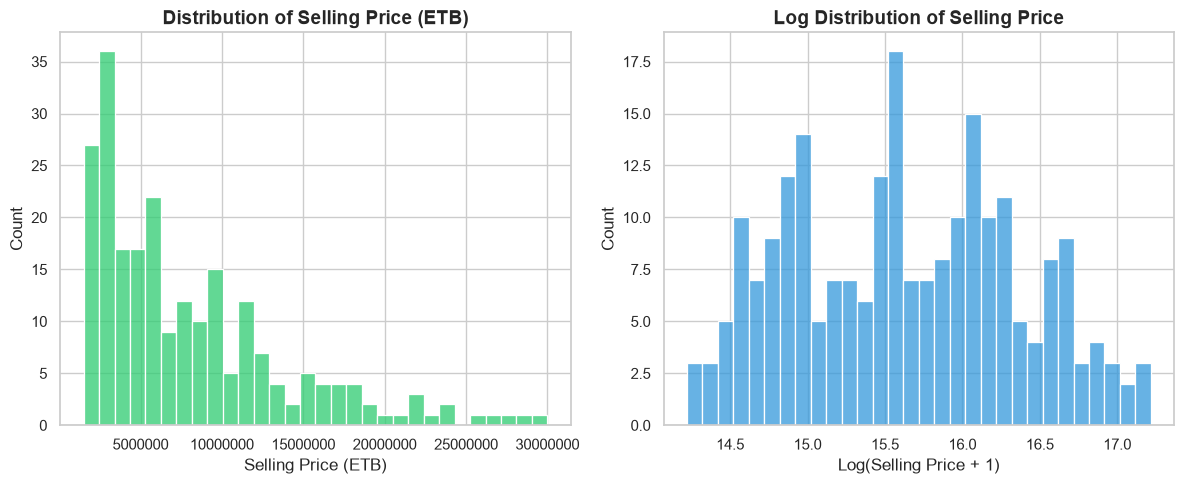

In [ ]:
# Distribution of Selling Prices (ETB)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(data['Selling_Price_ETB'], bins=30, color='#2ECC71', edgecolor='white')
plt.title('Distribution of Selling Price (ETB)', fontsize=14, fontweight='bold')
plt.xlabel('Selling Price (ETB)')
plt.ylabel('Count')
plt.ticklabel_format(style='plain', axis='x')

plt.subplot(1, 2, 2)
sns.histplot(np.log1p(data['Selling_Price_ETB']), bins=30, color='#3498DB', edgecolor='white')
plt.title('Log Distribution of Selling Price', fontsize=14, fontweight='bold')
plt.xlabel('Log(Selling Price + 1)')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

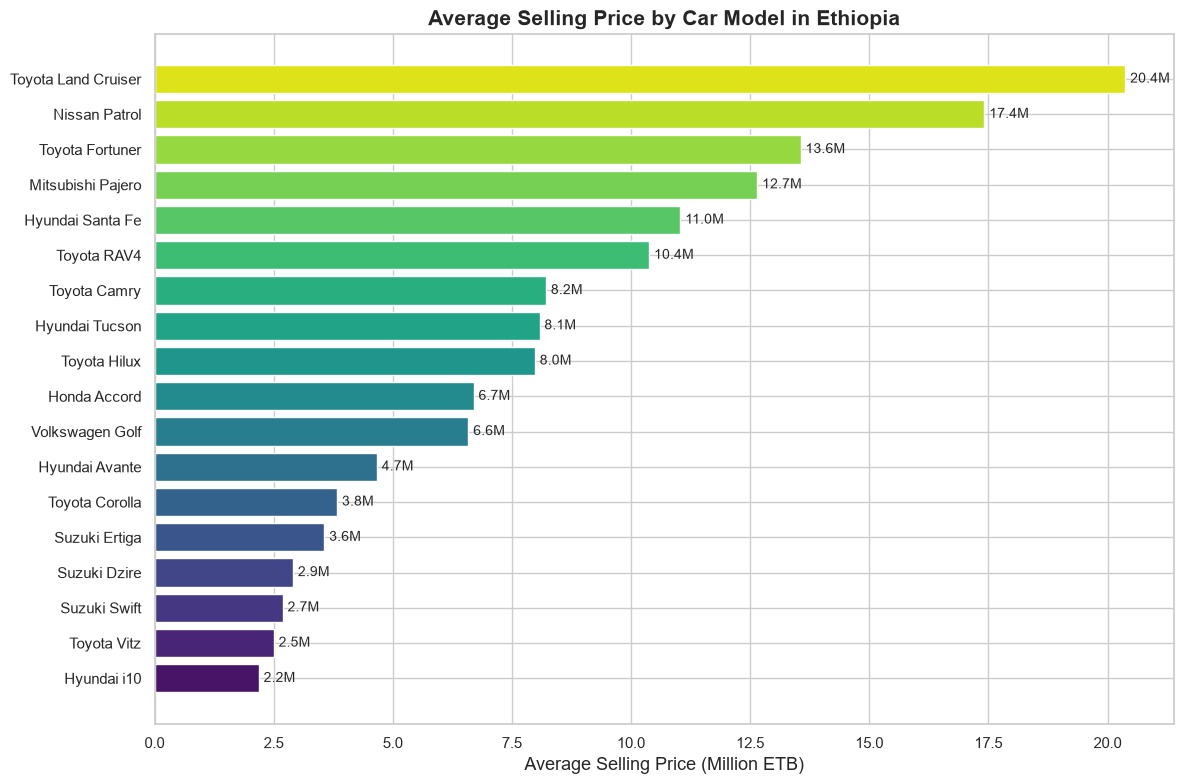

In [ ]:
# Average Selling Price by Car Model
avg_price = data.groupby('Car_Name')['Selling_Price_ETB'].mean().sort_values(ascending=True)

plt.figure(figsize=(12, 8))
bars = plt.barh(avg_price.index, avg_price.values / 1_000_000, color=sns.color_palette('viridis', len(avg_price)))
plt.xlabel('Average Selling Price (Million ETB)', fontsize=13)
plt.title('Average Selling Price by Car Model in Ethiopia', fontsize=15, fontweight='bold')
for bar, val in zip(bars, avg_price.values / 1_000_000):
    plt.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2,
             f'{val:.1f}M', va='center', fontsize=10)
plt.tight_layout()
plt.show()

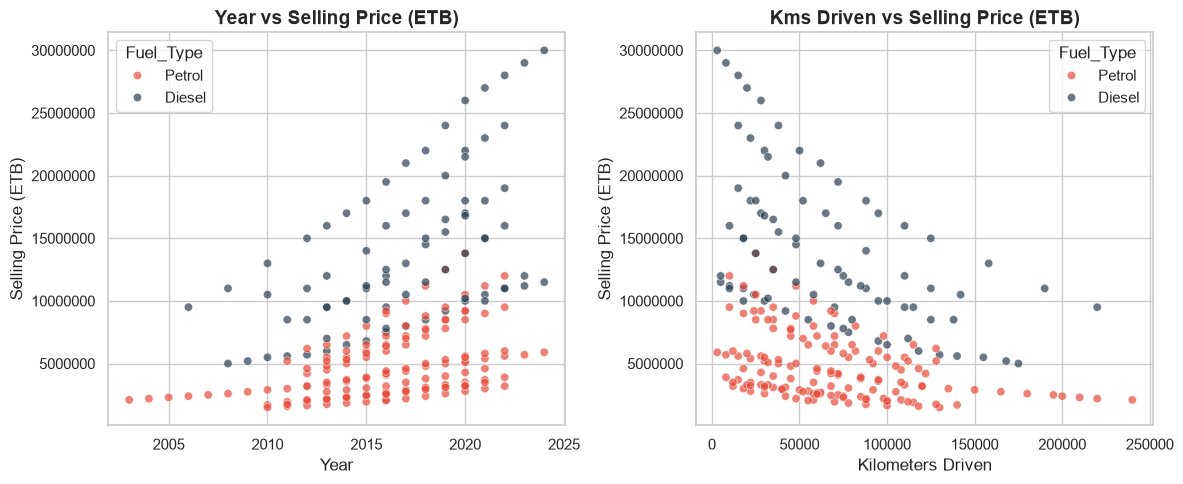

In [ ]:
# Year vs Selling Price
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.scatterplot(data=data, x='Year', y='Selling_Price_ETB', hue='Fuel_Type',
                palette={'Petrol': '#E74C3C', 'Diesel': '#2C3E50'}, alpha=0.7)
plt.title('Year vs Selling Price (ETB)', fontsize=14, fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Selling Price (ETB)')
plt.ticklabel_format(style='plain', axis='y')

plt.subplot(1, 2, 2)
sns.scatterplot(data=data, x='Kms_Driven', y='Selling_Price_ETB', hue='Fuel_Type',
                palette={'Petrol': '#E74C3C', 'Diesel': '#2C3E50'}, alpha=0.7)
plt.title('Kms Driven vs Selling Price (ETB)', fontsize=14, fontweight='bold')
plt.xlabel('Kilometers Driven')
plt.ylabel('Selling Price (ETB)')
plt.ticklabel_format(style='plain', axis='both')

plt.tight_layout()
plt.show()

C:\Users\User\AppData\Local\Temp\ipykernel_1812\2213420277.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=data, x='Fuel_Type', ax=axes[0], palette='Set2')
C:\Users\User\AppData\Local\Temp\ipykernel_1812\2213420277.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=data, x='Seller_Type', ax=axes[1], palette='Set1')
C:\Users\User\AppData\Local\Temp\ipykernel_1812\2213420277.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=data, x='Transmission', ax=axes[2], palette='Set3')


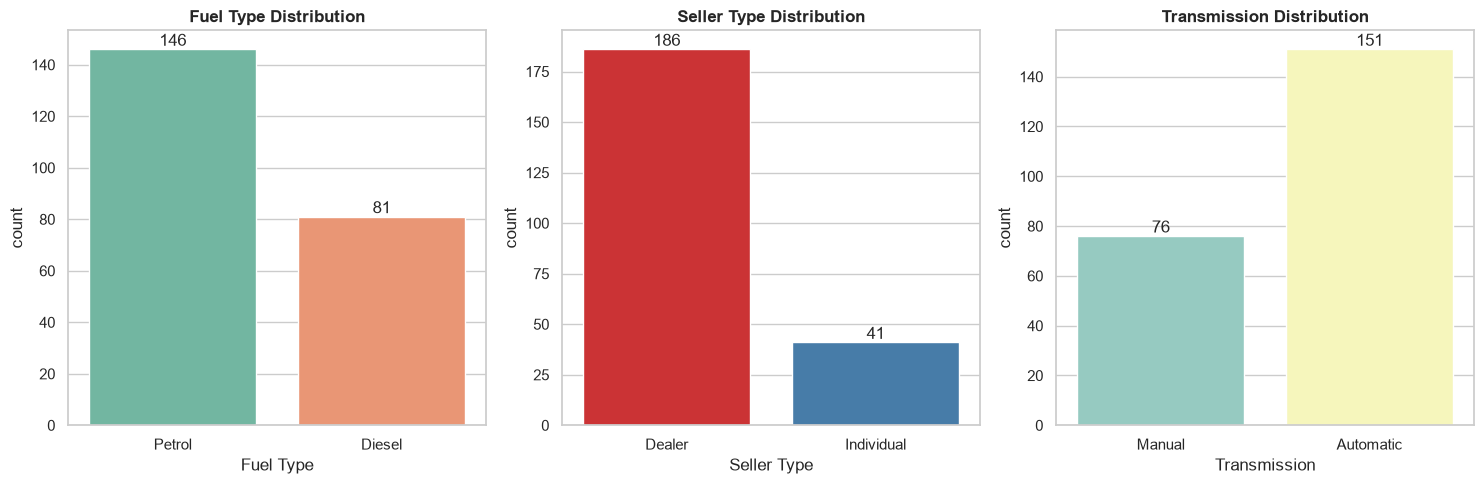

In [ ]:
# Categorical Variables - Count Plots
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Fuel Type
sns.countplot(data=data, x='Fuel_Type', ax=axes[0], palette='Set2')
axes[0].set_title('Fuel Type Distribution', fontweight='bold')
axes[0].set_xlabel('Fuel Type')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=12)

# Seller Type
sns.countplot(data=data, x='Seller_Type', ax=axes[1], palette='Set1')
axes[1].set_title('Seller Type Distribution', fontweight='bold')
axes[1].set_xlabel('Seller Type')
for p in axes[1].patches:
    axes[1].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=12)

# Transmission
sns.countplot(data=data, x='Transmission', ax=axes[2], palette='Set3')
axes[2].set_title('Transmission Distribution', fontweight='bold')
axes[2].set_xlabel('Transmission')
for p in axes[2].patches:
    axes[2].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=12)

plt.tight_layout()
plt.show()

C:\Users\User\AppData\Local\Temp\ipykernel_1812\3398333238.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, x='Fuel_Type', y='Selling_Price_ETB', ax=axes[0],
C:\Users\User\AppData\Local\Temp\ipykernel_1812\3398333238.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=data, x='Transmission', y='Selling_Price_ETB', ax=axes[1],


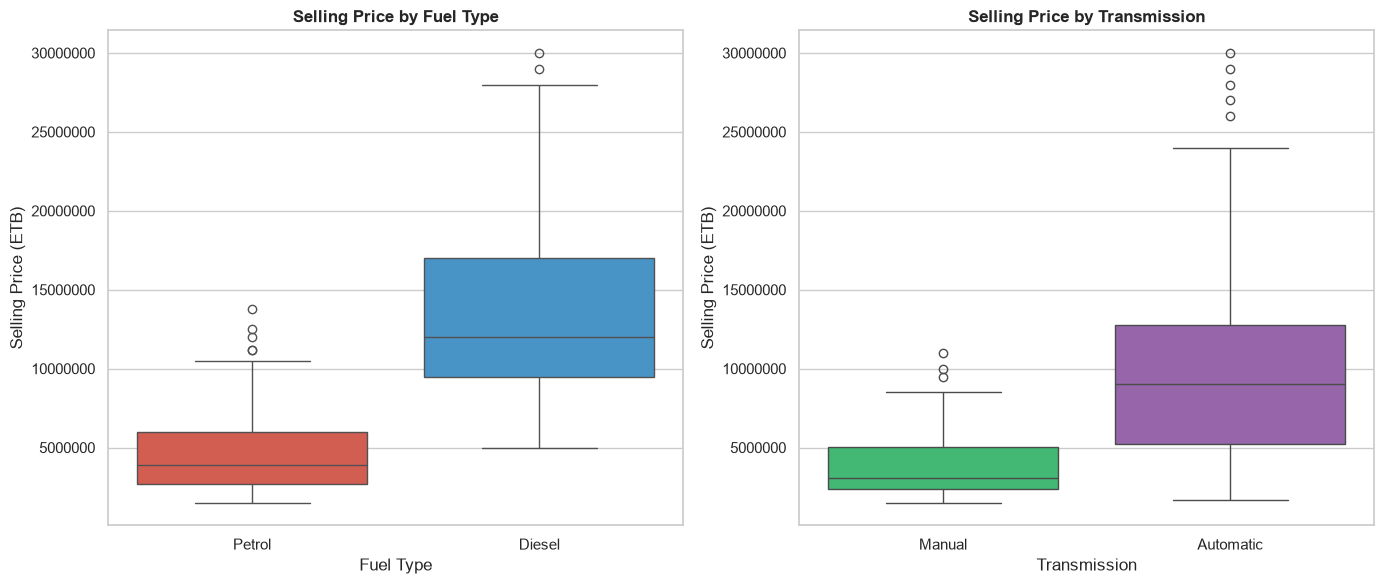

In [ ]:
# Selling Price by Fuel Type and Transmission (Box Plots)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(data=data, x='Fuel_Type', y='Selling_Price_ETB', ax=axes[0],
            palette={'Petrol': '#E74C3C', 'Diesel': '#3498DB'})
axes[0].set_title('Selling Price by Fuel Type', fontweight='bold')
axes[0].set_xlabel('Fuel Type')
axes[0].set_ylabel('Selling Price (ETB)')
axes[0].ticklabel_format(style='plain', axis='y')

sns.boxplot(data=data, x='Transmission', y='Selling_Price_ETB', ax=axes[1],
            palette={'Manual': '#2ECC71', 'Automatic': '#9B59B6'})
axes[1].set_title('Selling Price by Transmission', fontweight='bold')
axes[1].set_xlabel('Transmission')
axes[1].set_ylabel('Selling Price (ETB)')
axes[1].ticklabel_format(style='plain', axis='y')

plt.tight_layout()
plt.show()

## 5. Feature Engineering
We create a `Car_Age` feature to capture how old each car is.

In [ ]:
# Add Car_Age feature
current_year = 2024
data['Car_Age'] = current_year - data['Year']

print('Car_Age column added!')
data[['Car_Name', 'Year', 'Car_Age', 'Selling_Price_ETB']].head(10)

Car_Age column added!


,Car_Name,Year,Car_Age,Selling_Price_ETB
0,Toyota Corolla,2015,9,3800000
1,Toyota Corolla,2018,6,4800000
2,Toyota Corolla,2020,4,5200000
3,Toyota Corolla,2012,12,3200000
4,Toyota Corolla,2010,14,2900000
5,Toyota Corolla,2008,16,2600000
6,Toyota Corolla,2005,19,2300000
7,Toyota Corolla,2022,2,5600000
8,Toyota Corolla,2019,5,5000000
9,Toyota Corolla,2016,8,4100000


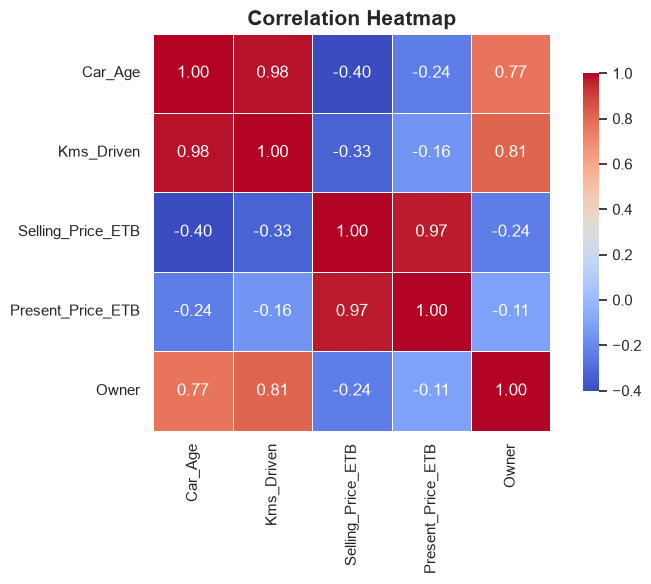

In [ ]:
# Correlation Heatmap (numeric columns)
numeric_cols = data[['Car_Age', 'Kms_Driven', 'Selling_Price_ETB', 'Present_Price_ETB', 'Owner']]
corr_matrix = numeric_cols.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=0.5, square=True, cbar_kws={'shrink': 0.8})
plt.title('Correlation Heatmap', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Data Preprocessing
- Drop non-numeric columns that are too granular (`Car_Name`, `Year`)
- One-hot encode categorical columns

In [ ]:
# Drop Car_Name and Year (Car_Age replaces Year)
df = data.drop(columns=['Car_Name', 'Year'])

# One-hot encode categorical columns
df = pd.get_dummies(df, columns=['Fuel_Type', 'Seller_Type', 'Transmission'], drop_first=True)

print('Preprocessed dataset shape:', df.shape)
print('\nColumns:', list(df.columns))
df.head()

Preprocessed dataset shape: (227, 8)

Columns: ['Selling_Price_ETB', 'Present_Price_ETB', 'Kms_Driven', 'Owner', 'Car_Age', 'Fuel_Type_Petrol', 'Seller_Type_Individual', 'Transmission_Manual']


,Selling_Price_ETB,Present_Price_ETB,Kms_Driven,Owner,Car_Age,Fuel_Type_Petrol,Seller_Type_Individual,Transmission_Manual
0,3800000,5200000,85000,0,9,True,False,True
1,4800000,5700000,45000,0,6,True,False,True
2,5200000,6000000,30000,0,4,True,False,True
3,3200000,5200000,120000,0,12,True,False,True
4,2900000,5200000,150000,1,14,True,True,True


## 7. Train-Test Split

In [ ]:
# Define features (X) and target (y)
X = df.drop(columns=['Selling_Price_ETB'])
y = df['Selling_Price_ETB']

# Split into train and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f'Training set size:  {X_train.shape[0]} samples')
print(f'Testing set size:   {X_test.shape[0]} samples')

Training set size:  181 samples
Testing set size:   46 samples


## 8. Training the Linear Regression Model

In [ ]:
# Train the model
model = LinearRegression()
model.fit(X_train, y_train)

print('Model trained successfully!')
print(f'Intercept: {model.intercept_:,.0f} ETB')

# Show feature coefficients
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
}).sort_values('Coefficient', ascending=False)

print('\n=== Feature Coefficients (ETB impact per unit) ===')
print(coef_df.to_string(index=False))

Model trained successfully!
Intercept: 1,248,366 ETB

=== Feature Coefficients (ETB impact per unit) ===
               Feature  Coefficient
     Present_Price_ETB     0.772315
      Fuel_Type_Petrol     0.000040
   Transmission_Manual    -0.000081
Seller_Type_Individual    -0.000152
                 Owner    -0.000244
               Car_Age    -0.002052
            Kms_Driven   -24.573056


## 9. Model Evaluation

In [ ]:
# Predictions on test set
y_pred = model.predict(X_test)

# Evaluation metrics
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print('='*50)
print('       MODEL EVALUATION RESULTS')
print('='*50)
print(f'  R² Score (Accuracy):     {r2:.4f}')
print(f'  Mean Absolute Error:     {mae:,.0f} ETB')
print(f'  Root Mean Squared Error: {rmse:,.0f} ETB')
print('='*50)
print(f'\n  MAE in millions: {mae/1_000_000:.2f}M ETB')
print(f'  RMSE in millions: {rmse/1_000_000:.2f}M ETB')

       MODEL EVALUATION RESULTS
  R² Score (Accuracy):     0.9473
  Mean Absolute Error:     729,788 ETB
  Root Mean Squared Error: 1,025,936 ETB

  MAE in millions: 0.73M ETB
  RMSE in millions: 1.03M ETB


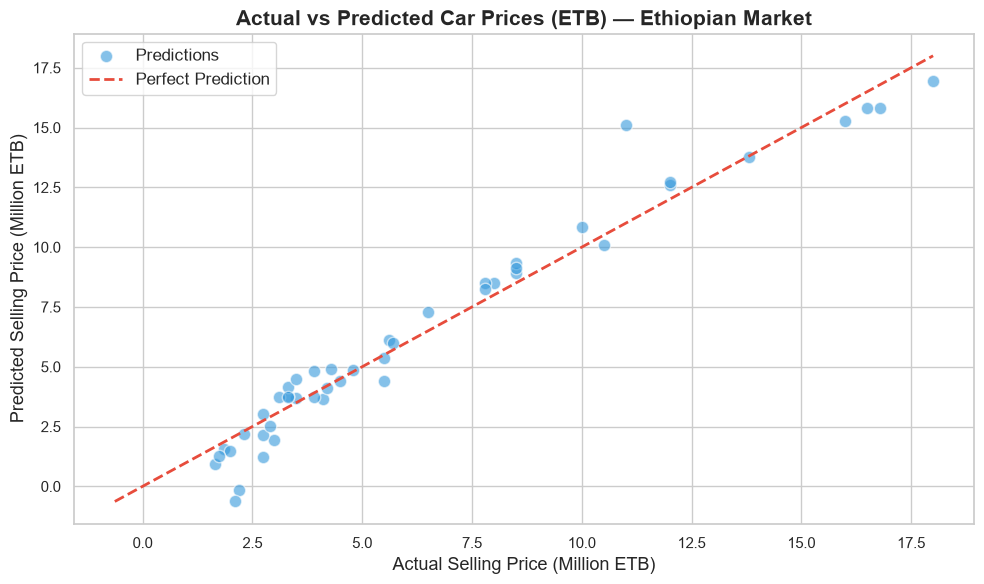

In [ ]:
# Actual vs Predicted Plot
plt.figure(figsize=(10, 6))
plt.scatter(y_test / 1_000_000, y_pred / 1_000_000,
            color='#3498DB', alpha=0.6, edgecolors='white', s=80, label='Predictions')

# Perfect prediction line
min_val = min(y_test.min(), y_pred.min()) / 1_000_000
max_val = max(y_test.max(), y_pred.max()) / 1_000_000
plt.plot([min_val, max_val], [min_val, max_val],
         color='#E74C3C', linestyle='--', linewidth=2, label='Perfect Prediction')

plt.xlabel('Actual Selling Price (Million ETB)', fontsize=13)
plt.ylabel('Predicted Selling Price (Million ETB)', fontsize=13)
plt.title('Actual vs Predicted Car Prices (ETB) — Ethiopian Market', fontsize=15, fontweight='bold')
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

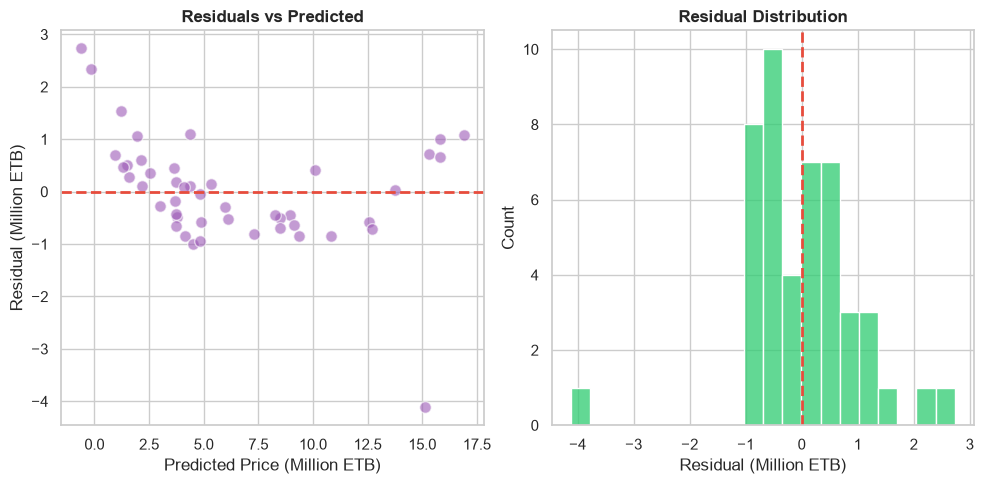

In [ ]:
# Residuals Plot
residuals = y_test - y_pred

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.scatter(y_pred / 1_000_000, residuals / 1_000_000,
            color='#9B59B6', alpha=0.6, edgecolors='white', s=70)
plt.axhline(y=0, color='#E74C3C', linestyle='--', linewidth=2)
plt.xlabel('Predicted Price (Million ETB)')
plt.ylabel('Residual (Million ETB)')
plt.title('Residuals vs Predicted', fontweight='bold')

plt.subplot(1, 2, 2)
sns.histplot(residuals / 1_000_000, bins=20, color='#2ECC71', edgecolor='white')
plt.axvline(x=0, color='#E74C3C', linestyle='--', linewidth=2)
plt.xlabel('Residual (Million ETB)')
plt.ylabel('Count')
plt.title('Residual Distribution', fontweight='bold')

plt.tight_layout()
plt.show()

## 10. 🇪🇹 Predict a Car Price
Let's use our trained model to predict the price of a specific Ethiopian car listing.

In [ ]:
def predict_price(present_price_etb, kms_driven, owner, car_age,
                  fuel_diesel=False, seller_individual=False, transmission_manual=False):
    """
    Predict the selling price of a used car in Ethiopia (ETB).
    
    Parameters:
    - present_price_etb : Current market / showroom price in ETB
    - kms_driven        : Total kilometers driven
    - owner             : Number of previous owners (0 = first owner)
    - car_age           : Age of the car in years (e.g., 2024 - 2015 = 9)
    - fuel_diesel       : True if Diesel, False if Petrol
    - seller_individual : True if Individual seller, False if Dealer
    - transmission_manual: True if Manual, False if Automatic
    """
    input_data = pd.DataFrame([{
        'Present_Price_ETB': present_price_etb,
        'Kms_Driven': kms_driven,
        'Owner': owner,
        'Car_Age': car_age,
        'Fuel_Type_Petrol': int(not fuel_diesel),
        'Seller_Type_Individual': int(seller_individual),
        'Transmission_Manual': int(transmission_manual)
    }])
    
    # Align with training columns
    input_data = input_data.reindex(columns=X.columns, fill_value=0)
    
    predicted = model.predict(input_data)[0]
    return max(0, predicted)  # Price can't be negative


# ────────────────────────────────────────────────
# Example 1: Toyota Corolla 2015, Petrol, 85,000 km
price_1 = predict_price(
    present_price_etb=5_200_000,
    kms_driven=85_000,
    owner=0,
    car_age=9,             # 2024 - 2015 = 9 years
    fuel_diesel=False,     # Petrol
    seller_individual=False,
    transmission_manual=True
)
print(f'Example 1 — Toyota Corolla 2015 (Petrol, 85,000 km):')
print(f'  Predicted Price: {price_1:,.0f} ETB  ({price_1/1_000_000:.2f}M ETB)')

print()

# ────────────────────────────────────────────────
# Example 2: Toyota Hilux 2020, Diesel, 30,000 km
price_2 = predict_price(
    present_price_etb=12_000_000,
    kms_driven=30_000,
    owner=0,
    car_age=4,             # 2024 - 2020 = 4 years
    fuel_diesel=True,      # Diesel
    seller_individual=False,
    transmission_manual=False  # Automatic
)
print(f'Example 2 — Toyota Hilux 2020 (Diesel, 30,000 km):')
print(f'  Predicted Price: {price_2:,.0f} ETB  ({price_2/1_000_000:.2f}M ETB)')

print()

# ────────────────────────────────────────────────
# Example 3: Hyundai i10 2017, Petrol, 48,000 km
price_3 = predict_price(
    present_price_etb=3_100_000,
    kms_driven=48_000,
    owner=0,
    car_age=7,             # 2024 - 2017 = 7 years
    fuel_diesel=False,     # Petrol
    seller_individual=False,
    transmission_manual=True
)
print(f'Example 3 — Hyundai i10 2017 (Petrol, 48,000 km):')
print(f'  Predicted Price: {price_3:,.0f} ETB  ({price_3/1_000_000:.2f}M ETB)')

Example 1 — Toyota Corolla 2015 (Petrol, 85,000 km):
  Predicted Price: 3,175,695 ETB  (3.18M ETB)

Example 2 — Toyota Hilux 2020 (Diesel, 30,000 km):
  Predicted Price: 9,778,956 ETB  (9.78M ETB)

Example 3 — Hyundai i10 2017 (Petrol, 48,000 km):
  Predicted Price: 2,463,037 ETB  (2.46M ETB)


## 11. Summary

### What We Built
A **Linear Regression model** trained on Ethiopian used car market data to predict selling prices in **Ethiopian Birr (ETB)**.

### Key Findings
- **Present_Price_ETB** (current showroom price) is the strongest predictor of selling price
- **Car_Age** has a significant negative effect — older cars sell for less
- **Diesel vehicles** tend to command higher prices (Toyota Hilux, Land Cruiser)
- **Kms_Driven** negatively impacts the selling price

### Ethiopian Market Context
- Toyota dominates the Ethiopian car market (Corolla, Hilux, Land Cruiser)
- Diesel 4x4s (Hilux, Patrol, Land Cruiser) are premium due to Ethiopia's terrain
- 1 USD ≈ 120 ETB (2024 rate post-devaluation)
- Data inspired by [mekina.net](https://www.mekina.net/) and [jiji.com.et](https://jiji.com.et/cars)

### Next Steps
- Collect more real listings from mekina.net / jiji.com.et
- Try advanced models (Random Forest, XGBoost) for better accuracy
- Add features: car condition, region (Addis Ababa, Dire Dawa, etc.), import status

In [ ]:
t